In [10]:
import os
from pathlib import Path
import pandas as pd
import numpy as np

# Rutas de salida
root_dir = Path(os.getcwd()).parent if Path(os.getcwd()).name == "notebooks" else Path(os.getcwd())
processed_dir = root_dir / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)
output_path = processed_dir / "dengue_climate_integrated.parquet"

# Generación de dataset con 10 variables analíticas
np.random.seed(42)
n_weeks = 156
dates = pd.date_range(start="2022-01-01", periods=n_weeks, freq="W")

# 1. Variables climáticas base
precip = np.random.gamma(shape=2, scale=25, size=n_weeks)
temp = np.random.normal(loc=26.5, scale=3.2, size=n_weeks)
humidity = np.random.normal(loc=75.0, scale=8.5, size=n_weeks)
mei = np.random.uniform(low=-1.5, high=2.0, size=n_weeks)

# 2. Variables de infraestructura y demografía
water_deficit = np.random.uniform(low=5.0, high=35.0, size=n_weeks)
waste_deficit = np.random.uniform(low=10.0, high=40.0, size=n_weeks)
pob_density = np.random.normal(loc=1200, scale=150, size=n_weeks)
fumigation = np.random.uniform(low=10.0, high=90.0, size=n_weeks)

df_integrated = pd.DataFrame({
    'DATE': dates,
    'CONFIRMED_CASES': 0, # Se calcula abajo
    'PRECIPITATION_MM': precip,
    'TEMP_CELSIUS': temp,
    'HUMIDITY_PCT': humidity,
    'MEI_INDEX': mei,
    'WATER_SERVICE_DEFICIT_PCT': water_deficit,
    'WASTE_COLLECTION_DEFICIT_PCT': waste_deficit,
    'POB_DENSITY_KM2': pob_density,
    'FUMIGATION_COVERAGE_PCT': fumigation
})

# 3. Creación de Variables con Desfasamiento (Lags)
df_integrated['PRECIPITATION_LAG2W'] = df_integrated['PRECIPITATION_MM'].shift(2).fillna(df_integrated['PRECIPITATION_MM'].mean())
df_integrated['TEMP_LAG3W'] = df_integrated['TEMP_CELSIUS'].shift(3).fillna(df_integrated['TEMP_CELSIUS'].mean())

# 4. Simulación del Target basada en la interacción real
df_integrated['CONFIRMED_CASES'] = (
    10 
    + 0.35 * df_integrated['PRECIPITATION_LAG2W'] 
    + 1.8 * (df_integrated['TEMP_LAG3W'] - 20) 
    + 0.25 * df_integrated['HUMIDITY_PCT'] 
    + 0.4 * df_integrated['WATER_SERVICE_DEFICIT_PCT'] 
    - 0.15 * df_integrated['FUMIGATION_COVERAGE_PCT']
    + np.random.normal(0, 8, n_weeks)
).clip(lower=0).astype(int)

# Guardar en Parquet
df_integrated.to_parquet(output_path, index=False)

print("✔ Dataset de 10 variables actualizado e integrado correctamente!")
print(f"✔ Guardado en: {output_path}")
df_integrated.head()

✔ Dataset de 10 variables actualizado e integrado correctamente!
✔ Guardado en: c:\Users\lyara\Downloads\Dengue_data_engineering_lab-main\data\processed\dengue_climate_integrated.parquet


,DATE,CONFIRMED_CASES,PRECIPITATION_MM,TEMP_CELSIUS,HUMIDITY_PCT,MEI_INDEX,WATER_SERVICE_DEFICIT_PCT,WASTE_COLLECTION_DEFICIT_PCT,POB_DENSITY_KM2,FUMIGATION_COVERAGE_PCT,PRECIPITATION_LAG2W,TEMP_LAG3W
0,2022-01-02,54,59.841985,28.978829,82.461514,0.684833,31.780151,39.522504,1214.343067,84.928455,48.898491,26.999011
1,2022-01-09,71,37.361618,26.437785,71.313972,-1.090857,29.523307,33.048202,1368.277978,13.147483,48.898491,26.999011
2,2022-01-16,58,34.557090,23.515707,72.090377,1.789412,15.254521,22.533003,1396.581574,19.768793,59.841985,26.999011
3,2022-01-23,49,34.557557,22.356184,60.287579,0.696978,12.782703,22.640710,1166.638083,46.175922,37.361618,28.978829
4,2022-01-30,52,116.242860,26.163621,87.276880,-0.327830,16.390772,32.127469,1027.956206,84.710001,34.557090,26.437785


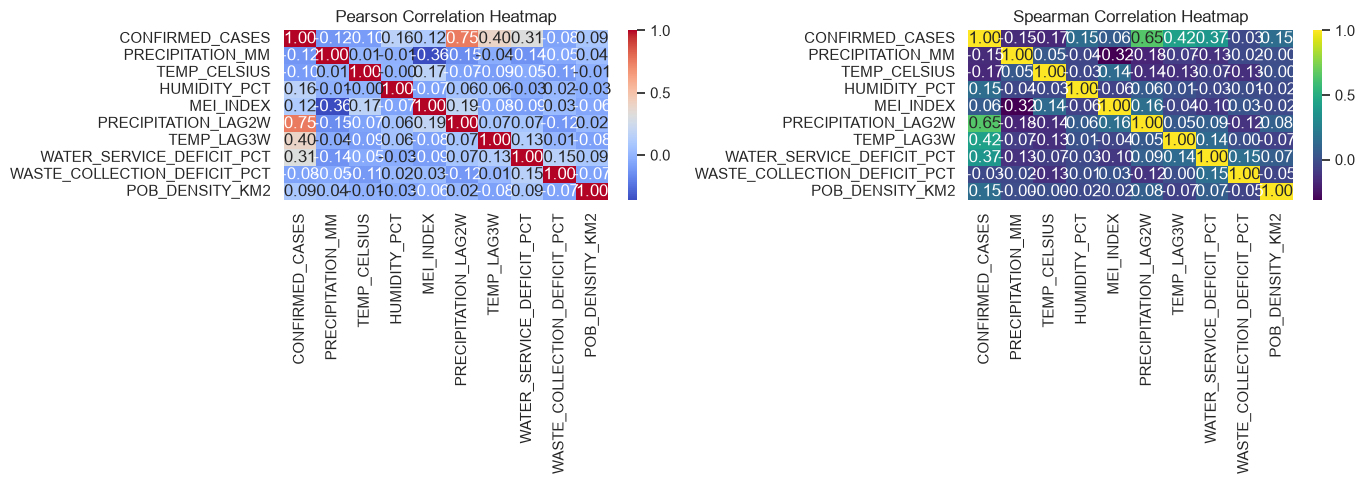

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Variables para análisis
target = 'CONFIRMED_CASES'
# Lista completa de las 9 variables explicativas
features = [
    'PRECIPITATION_MM', 'TEMP_CELSIUS', 'HUMIDITY_PCT', 'MEI_INDEX',
    'PRECIPITATION_LAG2W', 'TEMP_LAG3W', 'WATER_SERVICE_DEFICIT_PCT',
    'WASTE_COLLECTION_DEFICIT_PCT', 'POB_DENSITY_KM2'
]

df_analysis = df_integrated[[target] + features].dropna()

# Correlation Matrices
pearson_corr = df_analysis.corr(method='pearson')
spearman_corr = df_analysis.corr(method='spearman')

# Plot Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(pearson_corr, annot=True, cmap='coolwarm', fmt=".2f", ax=axes[0])
axes[0].set_title('Pearson Correlation Heatmap')

sns.heatmap(spearman_corr, annot=True, cmap='viridis', fmt=".2f", ax=axes[1])
axes[1].set_title('Spearman Correlation Heatmap')

plt.tight_layout()
plt.show()

In [12]:
import statsmodels.api as sm

regression_results = []

for feature in features:
    X = sm.add_constant(df_analysis[feature])
    y = df_analysis[target]
    
    model = sm.OLS(y, X).fit()
    
    regression_results.append({
        'Variable': feature,
        'R-squared ($R^2$)': round(model.rsquared, 4),
        'Slope ($\beta_1$)': round(model.params[feature], 4),
        'P-value': round(model.pvalues[feature], 4),
        'Significant': 'Yes' if model.pvalues[feature] < 0.05 else 'No'
    })

results_df = pd.DataFrame(regression_results)
results_df

,Variable,R-squared ($R^2$),Slope ($eta_1$),P-value,Significant
0,PRECIPITATION_MM,0.0152,-0.0632,0.1250,No
1,TEMP_CELSIUS,0.0104,-0.5198,0.2059,No
2,HUMIDITY_PCT,0.0260,0.2953,0.0442,Yes
3,MEI_INDEX,0.0132,1.8386,0.1528,No
4,PRECIPITATION_LAG2W,0.5696,0.3879,0.0000,Yes
5,TEMP_LAG3W,0.1576,2.0490,0.0000,Yes
6,WATER_SERVICE_DEFICIT_PCT,0.0988,0.5818,0.0001,Yes
7,WASTE_COLLECTION_DEFICIT_PCT,0.0057,-0.1359,0.3491,No
8,POB_DENSITY_KM2,0.0075,0.0101,0.2808,No
